IBL Brain-Wide Map

In [20]:
from one.api import ONE
from brainbox.io.one import SpikeSortingLoader
one = ONE(base_url='https://openalyx.internationalbrainlab.org')

In [ ]:
one = ONE(base_url='https://openalyx.internationalbrainlab.org')

one.load_cache(tag='Brainwidemap')
sessions = one.search()  # all sessions associated with the 'Brainwidemap' tag

# to return to the full cache containing an index of all IBL experiments
ONE.cache_clear()

Downloading: /Users/marilynjia/Downloads/ONE/openalyx.internationalbrainlab.org/Brainwidemap/tmp6uddethz/cache.zip Bytes: 4353173


100%|██████████| 4.1515092849731445/4.1515092849731445 [00:00<00:00,  6.05it/s]


In [22]:
# this is the query that yields the few recordings for the Rhomboid Nucleus (RH) region
insertions_rh = one.search_insertions(atlas_acronym='RH', datasets='spikes.times.npy', project='brainwide')

# if we want to extend the search to all thalamic regions, we can do the following
insertions_th = one.search_insertions(atlas_acronym='TH', datasets='spikes.times.npy', project='brainwide')

# the Allen brain regions parcellation is hierarchical, and searching for Thalamus will return all child Rhomboid Nucleus (RH) regions
assert set(insertions_rh).issubset(set(insertions_th))

In [23]:
# find sessions that have spikes.times datasets
sessions_with_spikes = one.search(project='brainwide', datasets='spikes.times.npy')
print(sessions_with_spikes[0])

ebce500b-c530-47de-8cb1-963c552703ea


In [24]:
pid = 'da8dfec1-d265-44e8-84ce-6ae9c109b8bd'
sl = SpikeSortingLoader(pid=pid, one=one)
spikes, clusters, channels = sl.load_spike_sorting()
clusters = sl.merge_clusters(spikes, clusters, channels)
good = clusters['cluster_id'][clusters['label'] == 1]

eid, pname = one.pid2eid(pid)
trials = one.load_object(eid, 'trials')
wheel = one.load_object(eid, 'wheel')

/Users/marilynjia/miniforge3/envs/ntab_fa26/lib/python3.13/site-packages/one/util.py:464: ALFWarning: Multiple revisions: "", "2025-03-03"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)


(<Figure size 1600x900 with 4 Axes>,
 array([[<Axes: title={'center': '2020-09-21_1_SWC_043_probe00, da8dfec1-d265-44e8-84ce-6ae9c109b8bd \n39_835_238 spikes, 1_143 clusters'}>,
         <Axes: >],
        [<Axes: xlabel='time (secs)', ylabel='depth (um)'>,
         <Axes: title={'center': 'alf'}>]], dtype=object))

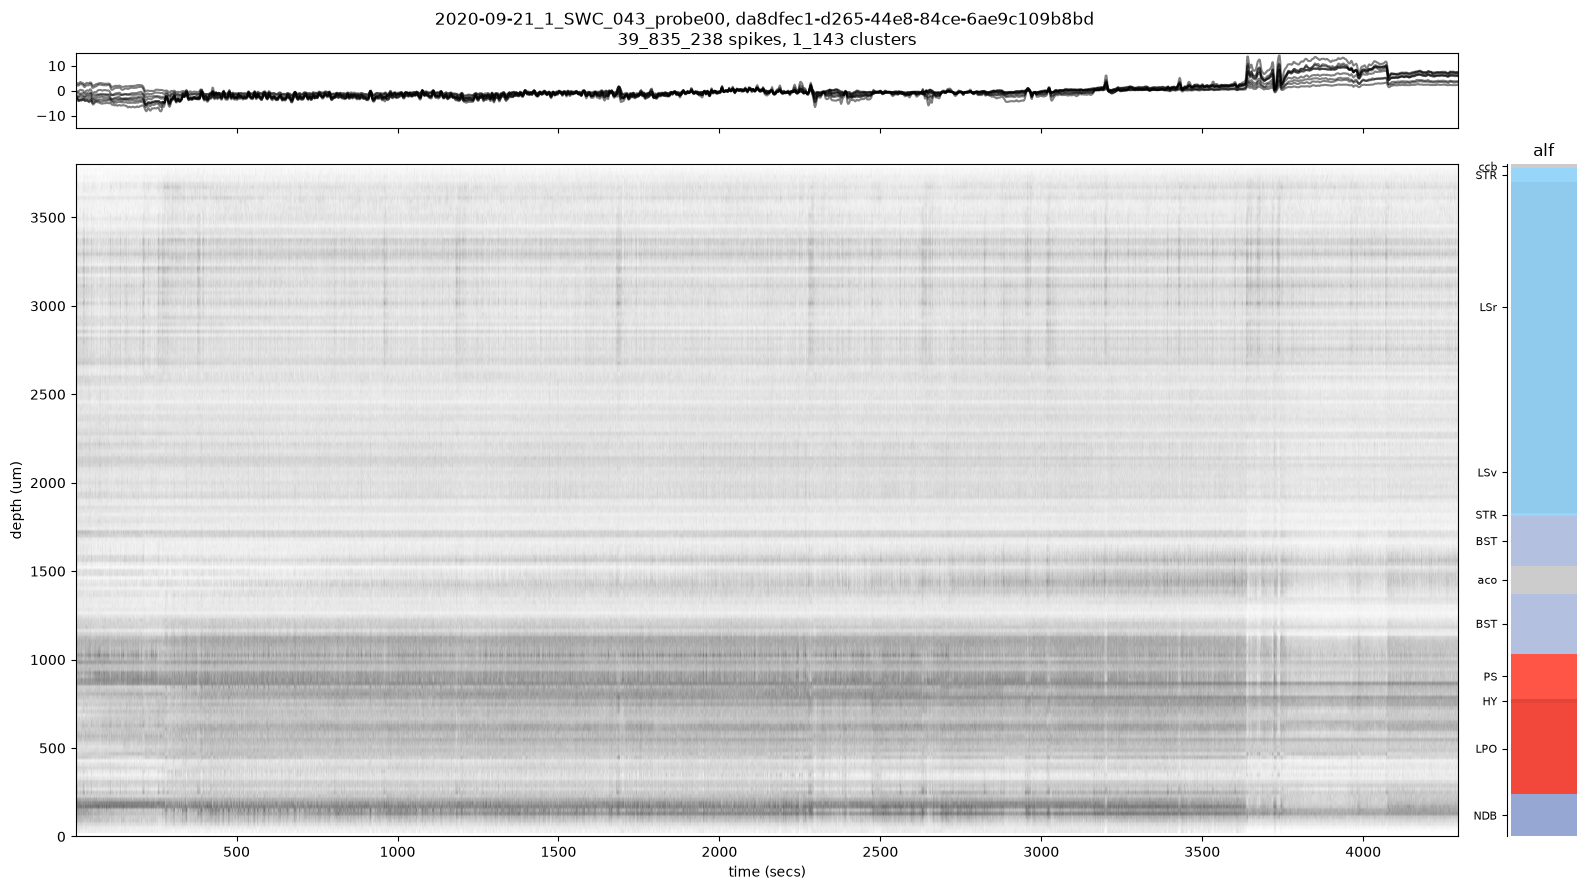

In [25]:
sl.raster(spikes, channels)